In [9]:



import pandas as pd
import urllib.request
import zipfile
import io
from IPython.display import display

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank.zip"

response = urllib.request.urlopen(url)

with zipfile.ZipFile(io.BytesIO(response.read())) as z:
    with z.open("bank-full.csv") as file:
        df = pd.read_csv(file, sep=";")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())



Dataset loaded successfully!
Rows and columns: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [10]:

# Step 2: Explore and check the dataset

print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nCustomer subscription counts:")
print(df["y"].value_counts())

print("\nDataset information:")
df.info()


Dataset shape:
(45211, 17)

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate rows:
0

Customer subscription counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    4521

Total customers: 45211
Customers subscribed: 5289
Customers not subscribed: 39922
Conversion rate: 11.70%


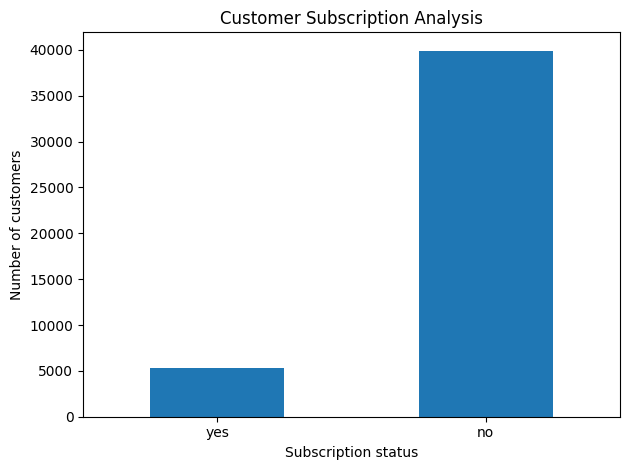

In [11]:

# Step 3: Analyze customer conversion

total_customers = len(df)

subscribed = (df["y"] == "yes").sum()
not_subscribed = (df["y"] == "no").sum()

conversion_rate = (subscribed / total_customers) * 100

print("Total customers:", total_customers)
print("Customers subscribed:", subscribed)
print("Customers not subscribed:", not_subscribed)
print(f"Conversion rate: {conversion_rate:.2f}%")

# Create a chart
subscription_counts = df["y"].value_counts().reindex(
    ["yes", "no"], fill_value=0
)

subscription_counts.plot(
    kind="bar",
    xlabel="Subscription status",
    ylabel="Number of customers",
    title="Customer Subscription Analysis",
    rot=0
)

plt.tight_layout()
plt.show()


Conversion rate by job category (%):


,Conversion Rate (%)
job,
student,28.68
retired,22.79
unemployed,15.50
management,13.76
admin.,12.20
self-employed,11.84
unknown,11.81
technician,11.06
services,8.88


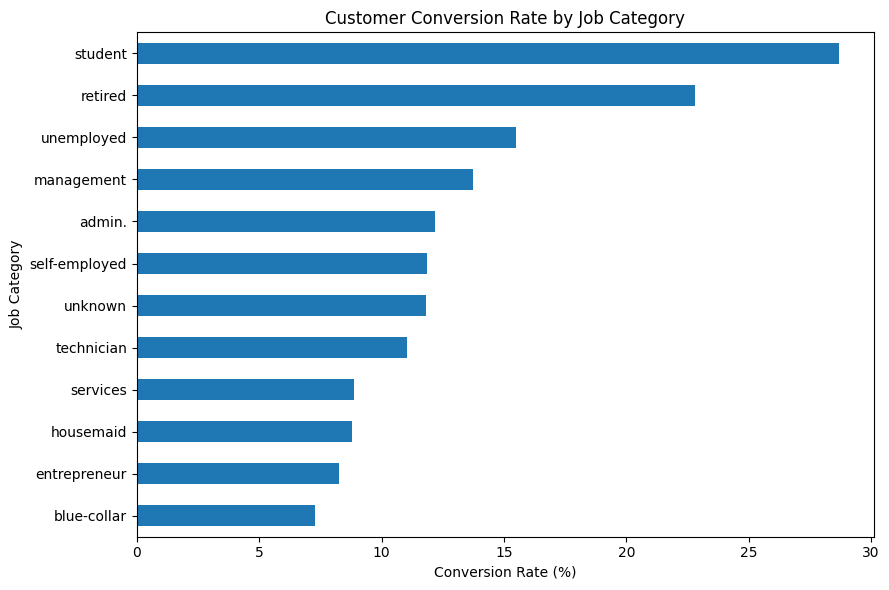

In [12]:

# Step 4: Conversion rate by job category

job_conversion = (
    df.assign(converted=(df["y"] == "yes").astype(int))
      .groupby("job")["converted"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print("Conversion rate by job category (%):")
display(job_conversion.round(2).to_frame("Conversion Rate (%)"))

# Create chart
job_conversion.sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Customer Conversion Rate by Job Category",
    xlabel="Conversion Rate (%)",
    ylabel="Job Category"
)

plt.tight_layout()
plt.show()


Monthly conversion rate (%):


,Conversion Rate (%)
month,
jan,10.12
feb,16.65
mar,51.99
apr,19.68
may,6.72
jun,10.22
jul,9.09
aug,11.01
sep,46.46


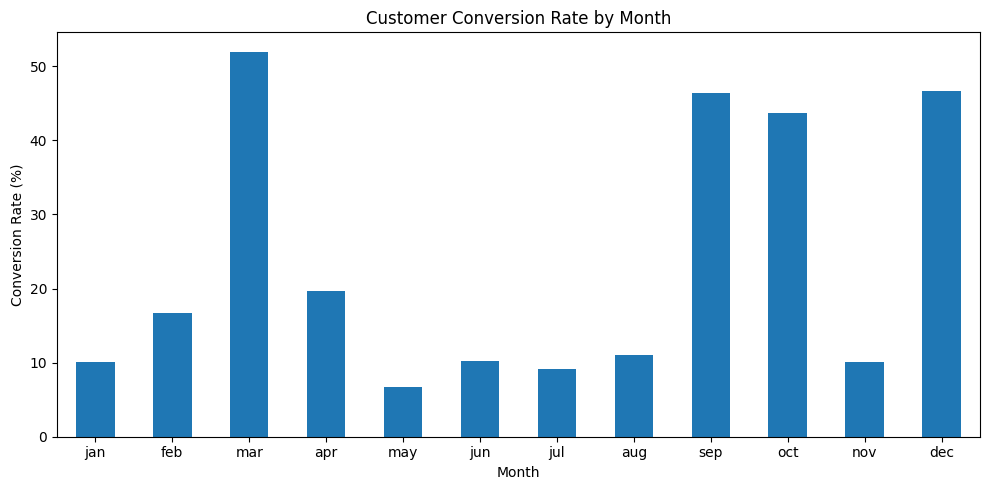

In [13]:

# Step 5: Analyze conversion rate by month

monthly_conversion = (
    df.assign(converted=(df["y"] == "yes").astype(int))
      .groupby("month")["converted"]
      .mean()
      .mul(100)
)

# Arrange months in calendar order
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

monthly_conversion = monthly_conversion.reindex(month_order).dropna()

print("Monthly conversion rate (%):")
display(monthly_conversion.round(2).to_frame("Conversion Rate (%)"))

monthly_conversion.plot(
    kind="bar",
    figsize=(10, 5),
    title="Customer Conversion Rate by Month",
    xlabel="Month",
    ylabel="Conversion Rate (%)",
    rot=0
)

plt.tight_layout()
plt.show()


Conversion rate by contact method (%):


,Conversion Rate (%)
contact,
cellular,14.92
telephone,13.42
unknown,4.07


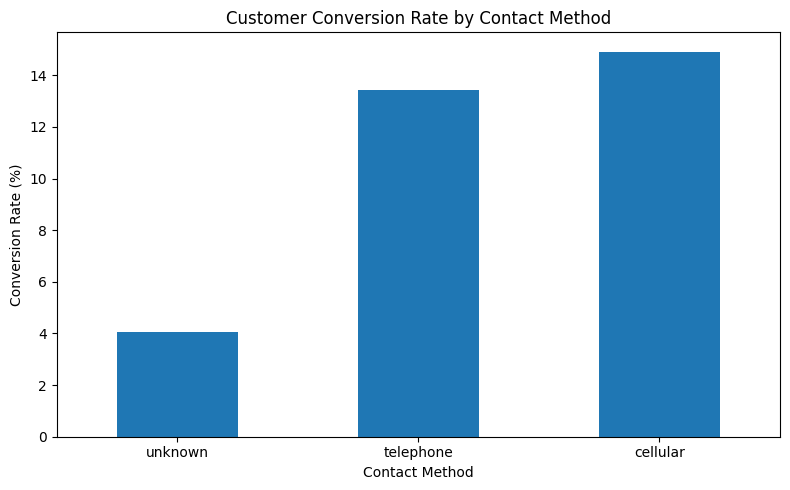

In [14]:

# Step 6: Conversion rate by contact method

contact_conversion = (
    df.assign(converted=(df["y"] == "yes").astype(int))
      .groupby("contact")["converted"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print("Conversion rate by contact method (%):")
display(contact_conversion.round(2).to_frame("Conversion Rate (%)"))

contact_conversion.sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Customer Conversion Rate by Contact Method",
    xlabel="Contact Method",
    ylabel="Conversion Rate (%)",
    rot=0
)

plt.tight_layout()
plt.show()


Conversion rate by previous campaign outcome (%):


,Conversion Rate (%)
poutcome,
success,64.73
other,16.68
failure,12.61
unknown,9.16


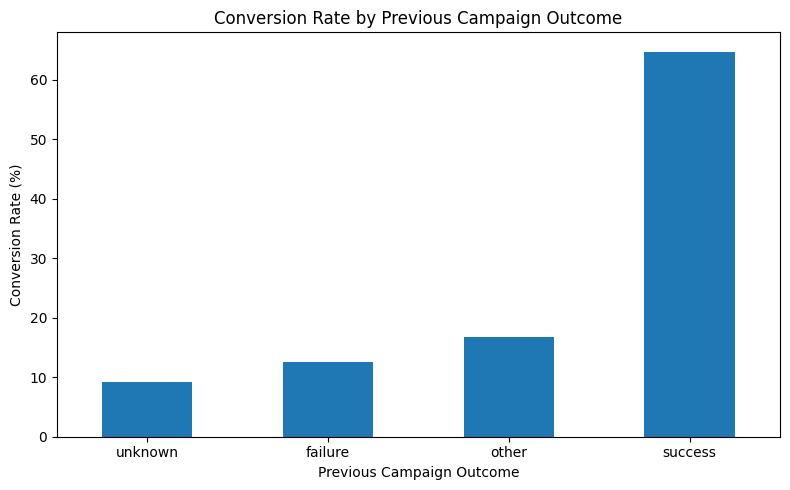

In [15]:

# Step 7: Conversion rate by previous campaign outcome

previous_conversion = (
    df.assign(converted=(df["y"] == "yes").astype(int))
      .groupby("poutcome")["converted"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print("Conversion rate by previous campaign outcome (%):")
display(
    previous_conversion.round(2).to_frame("Conversion Rate (%)")
)

previous_conversion.sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Conversion Rate by Previous Campaign Outcome",
    xlabel="Previous Campaign Outcome",
    ylabel="Conversion Rate (%)",
    rot=0
)

plt.tight_layout()
plt.show()


In [16]:

# Step 8: Key Findings and Business Recommendations

total = len(df)
yes_count = (df["y"] == "yes").sum()
no_count = (df["y"] == "no").sum()
conversion_rate = yes_count / total * 100

best_job = job_conversion.idxmax()
best_job_rate = job_conversion.max()

best_month = monthly_conversion.idxmax()
best_month_rate = monthly_conversion.max()

best_contact = contact_conversion.idxmax()
best_contact_rate = contact_conversion.max()

print("KEY FINDINGS")
print("-" * 40)
print(f"Total customers contacted: {total:,}")
print(f"Subscribed: {yes_count:,}")
print(f"Did not subscribe: {no_count:,}")
print(f"Overall conversion rate: {conversion_rate:.2f}%")
print(f"Highest-converting job category: {best_job} ({best_job_rate:.2f}%)")
print(f"Highest-converting month: {best_month} ({best_month_rate:.2f}%)")
print(f"Highest-converting contact method: {best_contact} ({best_contact_rate:.2f}%)")

print("\nBUSINESS RECOMMENDATIONS")
print("-" * 40)
print("1. Study successful customer segments to improve targeting.")
print("2. Test campaign timing using historical monthly conversion rates.")
print("3. Compare contact methods and prioritize those that perform well.")
print("4. Monitor conversion rates regularly to measure campaign effectiveness.")
print("5. Validate findings with future campaigns before changing strategy.")


KEY FINDINGS
----------------------------------------
Total customers contacted: 45,211
Subscribed: 5,289
Did not subscribe: 39,922
Overall conversion rate: 11.70%
Highest-converting job category: student (28.68%)
Highest-converting month: mar (51.99%)
Highest-converting contact method: cellular (14.92%)

BUSINESS RECOMMENDATIONS
----------------------------------------
1. Study successful customer segments to improve targeting.
2. Test campaign timing using historical monthly conversion rates.
3. Compare contact methods and prioritize those that perform well.
4. Monitor conversion rates regularly to measure campaign effectiveness.
5. Validate findings with future campaigns before changing strategy.



# Step 9: Project Summary

print("=" * 55)
print("MARKETING FUNNEL & CONVERSION PERFORMANCE ANALYSIS")
print("=" * 55)

print("""
OBJECTIVE:
Analyze a bank marketing campaign to understand customer
subscriptions and identify patterns associated with conversion.

DATASET:
UCI Bank Marketing dataset.

TOOLS USED:
Python, Pandas, Matplotlib, Google Colab.

ANALYSIS PERFORMED:
1. Dataset exploration and quality checks.
2. Overall customer conversion rate.
3. Conversion by job category.
4. Conversion by month.
5. Conversion by contact method.
6. Conversion by previous campaign outcome.

CONCLUSION:
The analysis helps compare customer segments and campaign
characteristics based on their subscription rates.

RECOMMENDATIONS:
- Focus on understanding high-performing customer segments.
- Evaluate campaign timing using historical data.
- Compare contact methods before allocating resources.
- Track campaign performance and validate results over time.

NOTE:
This analysis examines subscription outcomes in the available
dataset. It does not establish causation or guarantee future results.
""")
